In [2]:
import sys

!{sys.executable} -m pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to /private/var/folders/pb/htdt9q755p7gkt9wdkt0ypq00000gn/T/pip-req-build-bi2vjxdx
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /private/var/folders/pb/htdt9q755p7gkt9wdkt0ypq00000gn/T/pip-req-build-bi2vjxdx
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36637 sha256=cba078afe1888c2e2473739972f5e37723d1a4c039fd3fa976c38027a263bf8e
  Stored in directory: /private/var/folders/pb/htdt9q755p7gkt9wdkt0ypq00000gn/T/pip-ephem-wheel-cache-9eiff7ry/wheels/10/cf/59/9ccb2f0a1bcc81d4fbd0e501680b5d088d690c6cfbc02dc99d
Successfully built segment_anything


In [5]:
from pathlib import Path
import time
import urllib.request
import cv2
import numpy as np
from PIL import Image
import torch
from segment_anything import SamAutomaticMaskGenerator, sam_model_registry

# Define root and data paths
project_root = Path(
    "/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis"
)
cam_front_dir = project_root / "v1.0-mini/samples/CAM_FRONT/"
gt_output_dir = project_root / "sam_pseudo_gt_masks"
gt_output_dir.mkdir(parents=True, exist_ok=True)

# Gather up to 100 benchmark images
benchmark_images = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
print(f"Found {len(benchmark_images)} benchmark images in CAM_FRONT.")

Found 100 benchmark images in CAM_FRONT.


In [6]:
checkpoint_path = project_root / "sam_vit_b_01ec64.pth"
url = (
    "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
)

# Download checkpoint if not already present
if not checkpoint_path.exists():
  print(f"Downloading SAM checkpoint to: {checkpoint_path}...")
  urllib.request.urlretrieve(url, str(checkpoint_path))
  print("Download complete!")
else:
  print(f"Checkpoint already exists at: {checkpoint_path}")

# Setup device (Apple Silicon MPS or CPU)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Loading SAM model on device: {device}...")

sam = sam_model_registry["vit_b"](checkpoint=str(checkpoint_path)).to(device)
mask_generator = SamAutomaticMaskGenerator(
    model=sam, points_per_side=16, pred_iou_thresh=0.86
)
print("SAM model ready.")

Download complete!
Loading SAM model on device: mps...
SAM model ready.


In [9]:
import cv2
import numpy as np

# 1. Force SAM to use CPU for mask generation (bypasses MPS float64 limitations entirely)
device = torch.device("cpu")
print(f"Loading SAM model on device for stable preprocessing: {device}...")

sam = sam_model_registry["vit_b"](checkpoint=str(checkpoint_path)).to(device)
mask_generator = SamAutomaticMaskGenerator(
    model=sam, points_per_side=16, pred_iou_thresh=0.86
)
print("SAM model ready on CPU.")

# 2. Generate and Cache Pseudo-Ground Truth Masks safely
successful_count = 0
print(
    f"\nGenerating and saving pseudo-GT masks to folder: '{gt_output_dir}'..."
)

for idx, img_path in enumerate(benchmark_images):
  img_raw = cv2.imread(str(img_path))

  if img_raw is None:
    print(
        f"[Warning] OpenCV could not read image at {img_path}. Skipping..."
    )
    continue

  image_cv = cv2.cvtColor(img_raw, cv2.COLOR_BGR2RGB)
  height, width = image_cv.shape[:2]

  try:
    sam_masks = mask_generator.generate(image_cv)
  except Exception as e:
    print(f"[Error] Failed generating mask for {img_path.name}: {e}")
    continue

  # Create an integer label map proxy from SAM segments
  label_map = np.zeros((height, width), dtype=np.uint8)
  for m_idx, mask_dict in enumerate(sam_masks):
    label_map[mask_dict["segmentation"]] = (m_idx % 18) + 1

  # Save as a lossless PNG using the exact same image stem name
  save_path = gt_output_dir / f"{img_path.stem}.png"
  cv2.imwrite(str(save_path), label_map)
  successful_count += 1

  if (idx + 1) % 20 == 0 or (idx + 1) == len(benchmark_images):
    print(
        f"Processed and saved {successful_count}/{len(benchmark_images)}"
        " masks..."
    )

print(
    f"\nFinished! Successfully generated and cached {successful_count} pseudo-GT"
    " masks."
)

Loading SAM model on device for stable preprocessing: cpu...
SAM model ready on CPU.

Generating and saving pseudo-GT masks to folder: '/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/sam_pseudo_gt_masks'...
Processed and saved 20/100 masks...
Processed and saved 40/100 masks...
Processed and saved 60/100 masks...
Processed and saved 80/100 masks...
Processed and saved 100/100 masks...

Finished! Successfully generated and cached 100 pseudo-GT masks.


In [10]:
# Create cleanly paired lists for evaluation
image_paths = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
mask_paths = [gt_output_dir / f"{img.stem}.png" for img in image_paths]

print(f"Ready for evaluation!")
print(f"Total Images: {len(image_paths)}")
print(f"Total Ground-Truth Masks: {len(mask_paths)}")
print(f"Sample Mask Path: {mask_paths[0]}")

Ready for evaluation!
Total Images: 100
Total Ground-Truth Masks: 100
Sample Mask Path: /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/sam_pseudo_gt_masks/n008-2018-08-01-15-16-36-0400__CAM_FRONT__1533151603512404.png


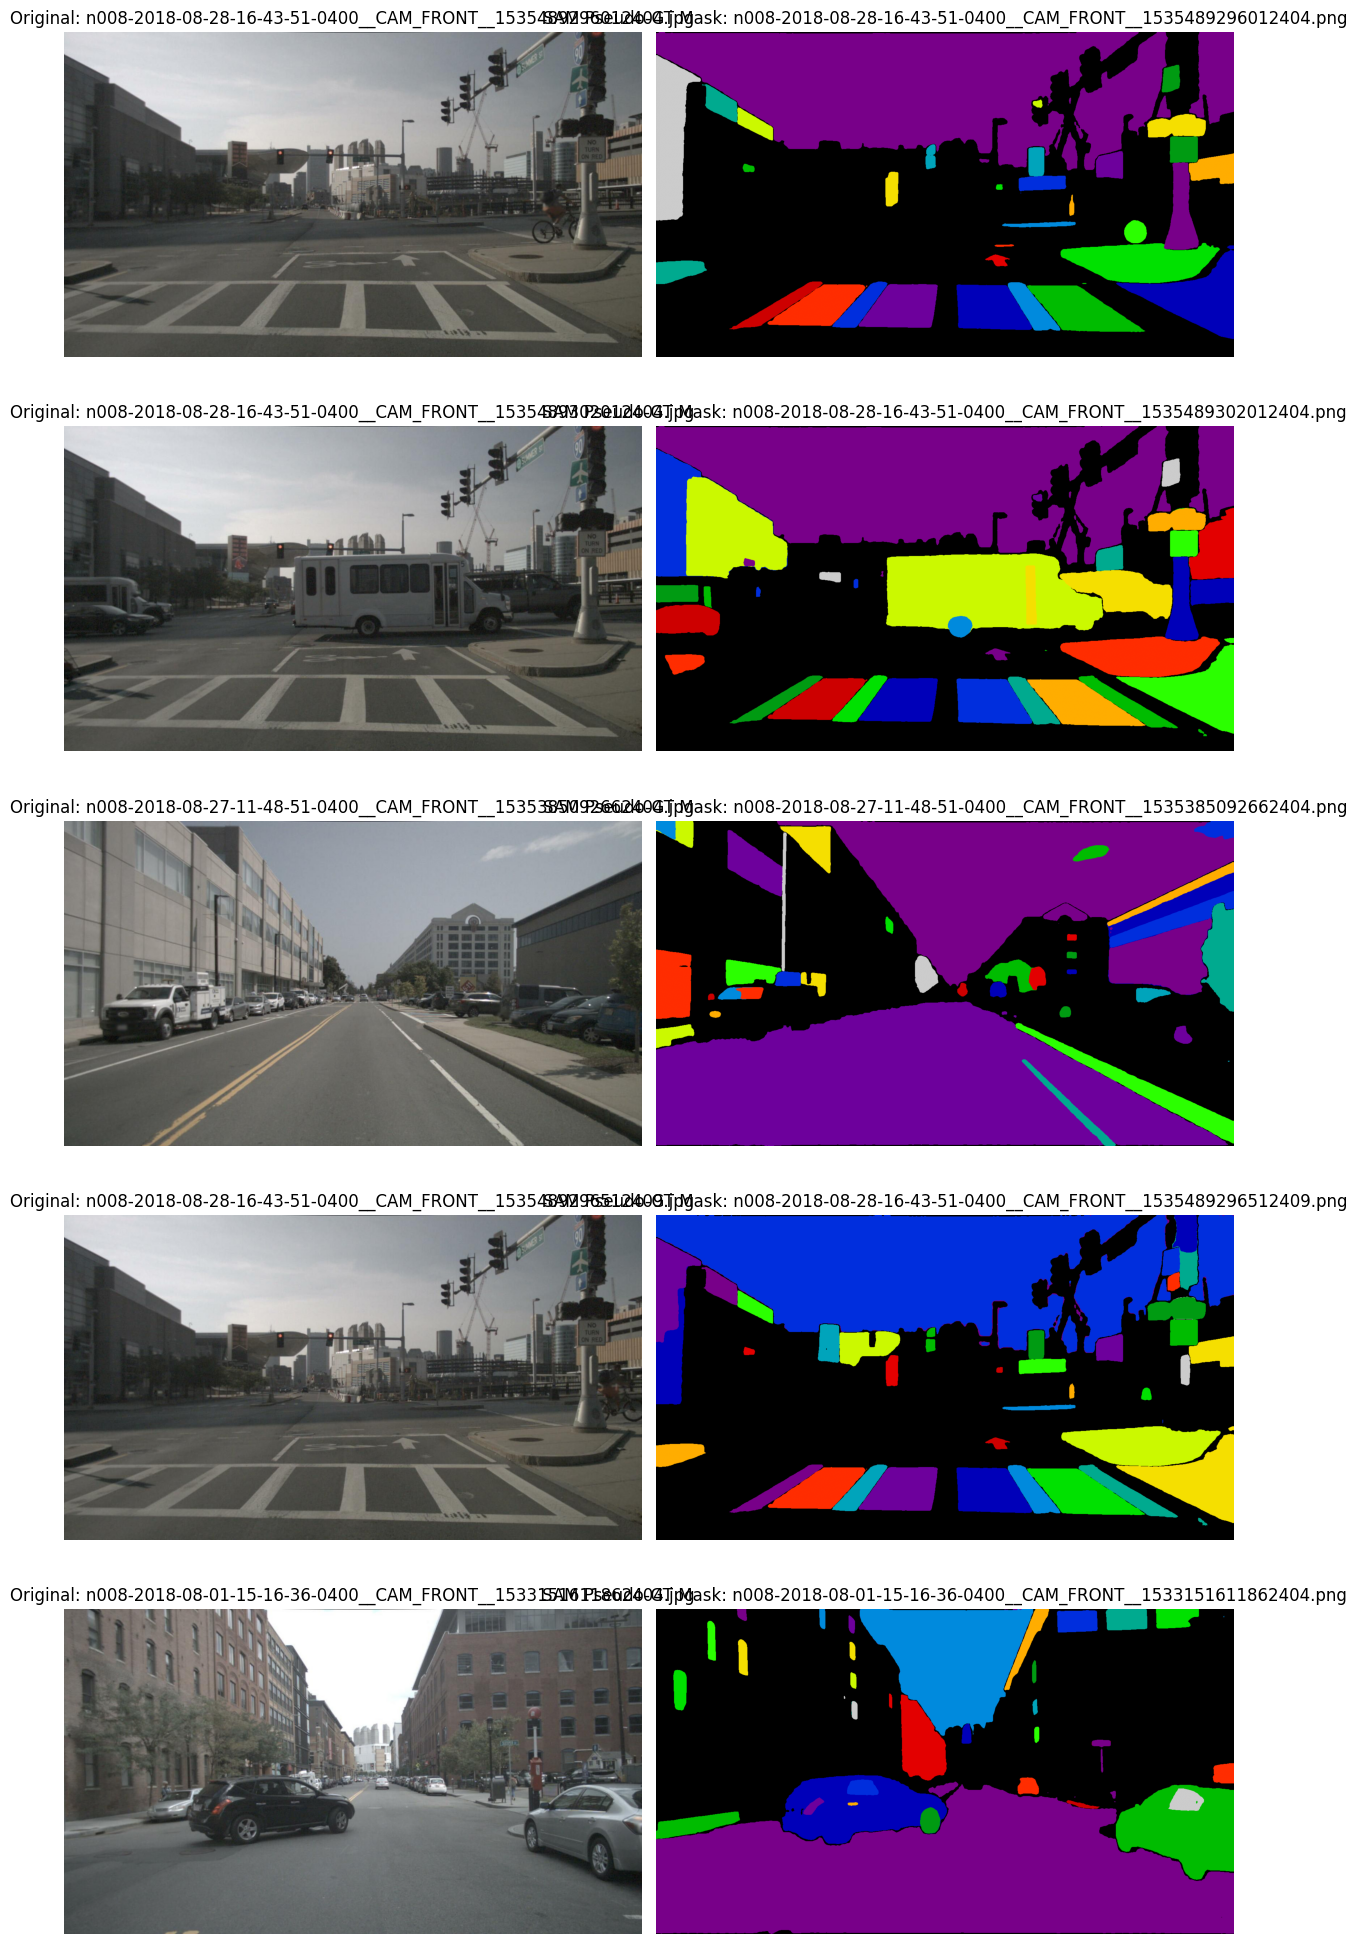

In [12]:
import random
import matplotlib.pyplot as plt
import numpy as np
import cv2

# 1. Grab all generated image/mask pairs
image_paths = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
paired_samples = [
    (img, gt_output_dir / f"{img.stem}.png")
    for img in image_paths
    if (gt_output_dir / f"{img.stem}.png").exists()
]

# 2. Randomly select 5 samples (or fewer if less are available)
sample_size = min(5, len(paired_samples))
selected_samples = random.sample(paired_samples, sample_size)

# 3. Plot them side-by-side
fig, axes = plt.subplots(sample_size, 2, figsize=(12, 4 * sample_size))

if sample_size == 1:
  axes = np.expand_dims(axes, 0)

for idx, (img_p, mask_p) in enumerate(selected_samples):
  # Load original image and mask (Fixed to cv2.IMREAD_UNCHANGED)
  orig_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)
  mask_img = cv2.imread(str(mask_p), cv2.IMREAD_UNCHANGED)

  # Plot Original Image
  axes[idx, 0].imshow(orig_img)
  axes[idx, 0].set_title(f"Original: {img_p.name}")
  axes[idx, 0].axis("off")

  # Plot Pseudo-GT Mask
  axes[idx, 1].imshow(mask_img, cmap="nipy_spectral")
  axes[idx, 1].set_title(f"SAM Pseudo-GT Mask: {img_p.stem}.png")
  axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()